<a href="https://colab.research.google.com/github/23070075-creator/NNDL-Lab/blob/main/NNDL_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 20, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 20, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 20, 1)          │            33 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,705 (49.63 KB)

 Trainable params: 12,705 (49.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.4213 - val_loss: 0.3151
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.1923 - val_loss: 0.0413
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0213 - val_loss: 0.0120
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0093 - val_loss: 0.0077
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0068 - val_loss: 0.0064
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0057 - val_loss: 0.0055
Epoch 7/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0050 - val_loss: 0.0049
Epoch 8/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0045 - val_loss: 0.0045
Epoch 9/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0041 - val_loss: 0.0040
Epoch 10/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0038 - val_loss: 0.0036
Epoch 11/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0036 - val_loss: 0.0034
Epoch 12/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0

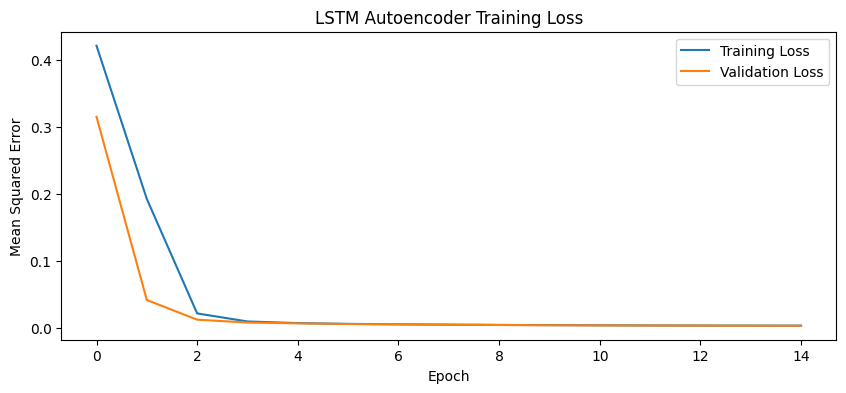

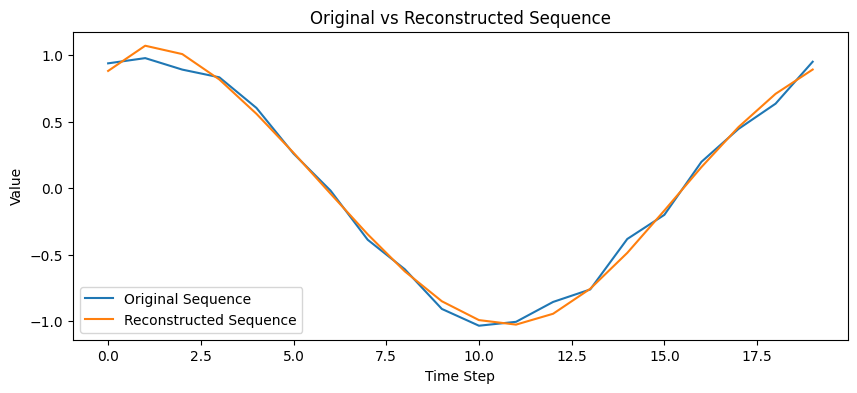

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense

np.random.seed(42)
tf.random.set_seed(42)

time_steps = 20
features = 1
samples = 2000

X = np.array([
    np.sin(np.linspace(0, 2 * np.pi, time_steps) + phase)
    for phase in np.random.uniform(0, 2 * np.pi, samples)
])

X = X.reshape(samples, time_steps, features)
X += np.random.normal(0, 0.05, X.shape)

train_size = int(0.8 * samples)
X_train = X[:train_size]
X_test = X[train_size:]

inputs = Input(shape=(time_steps, features))
encoded = LSTM(32, activation="tanh")(inputs)
decoded = RepeatVector(time_steps)(encoded)
decoded = LSTM(32, activation="tanh", return_sequences=True)(decoded)
outputs = TimeDistributed(Dense(features))(decoded)

autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

history = autoencoder.fit(
    X_train,
    X_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

reconstructed = autoencoder.predict(X_test)

mse = np.mean(np.square(X_test - reconstructed))
print("Test Reconstruction MSE:", mse)

plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("LSTM Autoencoder Training Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(X_test[0, :, 0], label="Original Sequence")
plt.plot(reconstructed[0, :, 0], label="Reconstructed Sequence")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.title("Original vs Reconstructed Sequence")
plt.legend()
plt.show()